# 01 — Exploratory Data Analysis

**Dataset:** Give Me Some Credit (`data/raw/cs-training.csv`)

This notebook has two parts:

- **Part 1 — Dataset inspection (Phase 2).** Structural facts about the whole file (SPEC §4.4): shape, types, the ID
  column, overall target rate, missing values, duplicates, special codes and invalid values. Nothing here looks at how
  features relate to the target.
- **Part 2 — Training-split EDA (Phase 3).** Distributions, relationships with the target and the analyst decisions
  that feed into cleaning and feature engineering. These use the **training split only** (SPEC §6), so the validation
  and test sets don't influence any decision.

All loading and splitting uses functions from `src/`; this notebook contains no pipeline logic.

# Part 1 — Dataset inspection

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd

from src import config
from src.data_loader import file_sha256, load_raw_data

pd.set_option("display.width", 200, "display.max_columns", 50, "display.float_format", "{:,.4f}".format)

## 1. File integrity and schema

In [2]:
data_hash = file_sha256(config.RAW_DATA_FILE)
print("SHA-256:", data_hash)
print("Matches expected hash:", data_hash == config.EXPECTED_DATA_SHA256)

raw = pd.read_csv(config.RAW_DATA_FILE)  # as stored on disk, before validation
print("Raw shape:", raw.shape)
raw.dtypes.to_frame("dtype")

SHA-256: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac
Matches expected hash: True


Raw shape: (150000, 12)


,dtype
Unnamed: 0,int64
SeriousDlqin2yrs,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64
NumberRealEstateLoansOrLines,int64


The first column has an empty header (pandas names it `Unnamed: 0`). Check that it is just a row counter:

In [3]:
id_col = raw.columns[0]
print(f"{id_col!r}: unique={raw[id_col].is_unique}, equals 1..n={np.array_equal(raw[id_col], np.arange(1, len(raw) + 1))}")

'Unnamed: 0': unique=True, equals 1..n=True


`load_raw_data` validates the schema, makes the row ID the index (so it can never become a feature) and renames
the target `SeriousDlqin2yrs` → `default`.

In [4]:
df = load_raw_data()
features = config.RAW_FEATURES
print(df.shape)
print("Index:", df.index.name)
print("Columns:", list(df.columns))

(150000, 11)
Index: row_id
Columns: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'default']


## 2. Target distribution (whole file)

In [5]:
counts = df[config.TARGET].value_counts().rename("rows").to_frame()
counts["share"] = counts["rows"] / len(df)
counts

,rows,share
default,,
0,139974,0.9332
1,10026,0.0668


## 3. Missing values

In [6]:
missing = df[features].isna().sum()
pd.DataFrame({"missing": missing, "pct": missing / len(df) * 100}).query("missing > 0")

,missing,pct
MonthlyIncome,29731,19.8207
NumberOfDependents,3924,2.6160


In [7]:
income_missing = df["MonthlyIncome"].isna()
deps_missing = df["NumberOfDependents"].isna()
print("Rows missing dependents:", deps_missing.sum())
print("...of which also missing income:", (deps_missing & income_missing).sum())

Rows missing dependents: 3924
...of which also missing income: 3924


## 4. Duplicate rows (ignoring the row ID)

In [8]:
full_dups = df.duplicated()
feature_dups = df[features].duplicated()
conflicts = (
    df[df[features].duplicated(keep=False)]
    .groupby(features, dropna=False)[config.TARGET].nunique()
    .gt(1).sum()
)
print("Duplicate rows (features + target):", full_dups.sum())
print("Duplicate feature profiles:", feature_dups.sum())
print("Duplicate profiles with conflicting targets:", conflicts)
print("Duplicate rows with MonthlyIncome missing:", df.loc[full_dups, "MonthlyIncome"].isna().sum())

Duplicate rows (features + target): 609
Duplicate feature profiles: 646
Duplicate profiles with conflicting targets: 37
Duplicate rows with MonthlyIncome missing: 510


In [9]:
# What duplicated rows look like, summarised (no individual records are displayed,
# because Kaggle's rules restrict redistributing the data)
dup_rows = df.loc[df[features].duplicated(keep=False), features]
group_sizes = dup_rows.value_counts(dropna=False)
print("Rows involved in duplicated profiles:", len(dup_rows), "| distinct profiles:", len(group_sizes),
      "| largest group:", group_sizes.max())
dup_rows.describe().T[["mean", "50%", "max"]]

Rows involved in duplicated profiles: 1000 | distinct profiles: 354 | largest group: 12


,mean,50%,max
RevolvingUtilizationOfUnsecuredLines,0.5020,1.0000,1.0000
age,50.1910,52.0000,99.0000
NumberOfTime30-59DaysPastDueNotWorse,7.3500,0.0000,98.0000
DebtRatio,1.6829,0.0000,520.0000
MonthlyIncome,753.6533,820.0000,"3,500.0000"
NumberOfOpenCreditLinesAndLoans,1.5580,1.0000,10.0000
NumberOfTimes90DaysLate,7.3800,0.0000,98.0000
NumberRealEstateLoansOrLines,0.0000,0.0000,0.0000
NumberOfTime60-89DaysPastDueNotWorse,7.3500,0.0000,98.0000
NumberOfDependents,0.0096,0.0000,2.0000


## 5. Summary statistics

In [10]:
df[features].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
RevolvingUtilizationOfUnsecuredLines,"150,000.0000",6.0484,249.7554,0.0000,0.0000,0.1542,1.0930,"50,708.0000"
age,"150,000.0000",52.2952,14.7719,0.0000,24.0000,52.0000,87.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,"150,000.0000",0.4210,4.1928,0.0000,0.0000,0.0000,4.0000,98.0000
DebtRatio,"150,000.0000",353.0051,"2,037.8185",0.0000,0.0000,0.3665,"4,979.0400","329,664.0000"
MonthlyIncome,"120,269.0000","6,670.2212","14,384.6742",0.0000,0.0000,"5,400.0000","25,000.0000","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,"150,000.0000",8.4528,5.1460,0.0000,0.0000,8.0000,24.0000,58.0000
NumberOfTimes90DaysLate,"150,000.0000",0.2660,4.1693,0.0000,0.0000,0.0000,3.0000,98.0000
NumberRealEstateLoansOrLines,"150,000.0000",1.0182,1.1298,0.0000,0.0000,1.0000,4.0000,54.0000
NumberOfTime60-89DaysPastDueNotWorse,"150,000.0000",0.2404,4.1552,0.0000,0.0000,0.0000,2.0000,98.0000
NumberOfDependents,"146,076.0000",0.7572,1.1151,0.0000,0.0000,0.0000,4.0000,20.0000


In [11]:
counts_cols = [c for c in features if c not in ("RevolvingUtilizationOfUnsecuredLines", "DebtRatio")]
pd.DataFrame({
    "all_integer": {c: bool((df[c].dropna() % 1 == 0).all()) for c in counts_cols},
    "negatives": {c: int((df[c] < 0).sum()) for c in counts_cols},
})

,all_integer,negatives
age,True,0
NumberOfTime30-59DaysPastDueNotWorse,True,0
MonthlyIncome,True,0
NumberOfOpenCreditLinesAndLoans,True,0
NumberOfTimes90DaysLate,True,0
NumberRealEstateLoansOrLines,True,0
NumberOfTime60-89DaysPastDueNotWorse,True,0
NumberOfDependents,True,0


## 6. Special codes 96 / 98 in the past-due counts

In [12]:
for col in config.PAST_DUE_COLUMNS:
    high = df.loc[df[col] >= 14, col].value_counts().sort_index().to_dict()
    print(f"{col}: values >= 14 -> {high}; largest value below 90 = {df.loc[df[col] < 90, col].max()}")

coded = df[config.PAST_DUE_COLUMNS].ge(90)
print("\nRows with any 96/98 code:", coded.any(axis=1).sum())
print("Rows where all three columns are coded:", coded.all(axis=1).sum())

NumberOfTime30-59DaysPastDueNotWorse: values >= 14 -> {96: 5, 98: 264}; largest value below 90 = 13
NumberOfTime60-89DaysPastDueNotWorse: values >= 14 -> {96: 5, 98: 264}; largest value below 90 = 11
NumberOfTimes90DaysLate: values >= 14 -> {14: 2, 15: 2, 17: 1, 96: 5, 98: 264}; largest value below 90 = 17

Rows with any 96/98 code: 269
Rows where all three columns are coded: 269


In [13]:
# What the coded rows look like (feature values only)
df.loc[coded.any(axis=1), features].describe().T[["mean", "min", "50%", "max"]]

,mean,min,50%,max
RevolvingUtilizationOfUnsecuredLines,1.0000,1.0000,1.0000,1.0000
age,34.2454,21.0000,29.0000,79.0000
NumberOfTime30-59DaysPastDueNotWorse,97.9628,96.0000,98.0000,98.0000
DebtRatio,5.7397,0.0000,0.0000,255.0000
MonthlyIncome,"2,557.1351",0.0000,"2,168.5000","28,733.0000"
NumberOfOpenCreditLinesAndLoans,0.0074,0.0000,0.0000,1.0000
NumberOfTimes90DaysLate,97.9628,96.0000,98.0000,98.0000
NumberRealEstateLoansOrLines,0.0000,0.0000,0.0000,0.0000
NumberOfTime60-89DaysPastDueNotWorse,97.9628,96.0000,98.0000,98.0000
NumberOfDependents,0.3697,0.0000,0.0000,5.0000


## 7. Age

In [14]:
print("age < 18:", df.loc[df["age"] < 18, "age"].value_counts().to_dict())
print("age > 100:", df.loc[df["age"] > 100, "age"].value_counts().sort_index().to_dict())

age < 18: {0: 1}
age > 100: {101: 3, 102: 3, 103: 3, 105: 1, 107: 1, 109: 2}


## 8. Utilization, debt ratio and income

In [15]:
util = df["RevolvingUtilizationOfUnsecuredLines"]
print(f"Utilization > 1: {(util > 1).sum():,}   > 10: {(util > 10).sum():,}   max: {util.max():,.0f}")

income_zero = df["MonthlyIncome"].eq(0)
pd.DataFrame({
    "rows": [(~income_missing & ~income_zero).sum(), income_zero.sum(), income_missing.sum()],
    "DebtRatio median": [
        df.loc[~income_missing & ~income_zero, "DebtRatio"].median(),
        df.loc[income_zero, "DebtRatio"].median(),
        df.loc[income_missing, "DebtRatio"].median(),
    ],
}, index=["income > 0", "income == 0", "income missing"])

Utilization > 1: 3,321   > 10: 241   max: 50,708


,rows,DebtRatio median
income > 0,118635,0.2925
income == 0,1634,930.0000
income missing,29731,"1,159.0000"


In [16]:
print("NumberRealEstateLoansOrLines > NumberOfOpenCreditLinesAndLoans:",
      (df["NumberRealEstateLoansOrLines"] > df["NumberOfOpenCreditLinesAndLoans"]).sum())
print("Infinite values:", np.isinf(df[features]).sum().sum())

NumberRealEstateLoansOrLines > NumberOfOpenCreditLinesAndLoans: 0
Infinite values: 0


## 9. Train / validation / test split (SPEC §5.1)

Produced by `python -m src.data_loader`:

In [17]:
summary = json.loads(config.SPLIT_SUMMARY_PATH.read_text())
pd.DataFrame(summary["splits"]).T

,rows,defaults,default_rate,row_id_sha256,rows_with_identical_profile_in_train
train,105000,7018,0.0668,31b887cd264f7970884de9939a50b6af8b80175f9fc0f1...,NaN
validation,22500,1504,0.0668,c0617f96f1a3abe8d455c52db07891c8f92c94aebe98b3...,126
test,22500,1504,0.0668,729d63cf3f7f18d3eed7564c0a12249cf03f28465b6784...,129


## Part 1 findings

| Check | Result |
|---|---|
| Shape | 150,000 rows × 12 columns: row ID, target, 10 features. Matches the documented schema exactly |
| Row ID | Unnamed first column, values 1…150,000, unique. Used as the index, never as a feature |
| Data types | All numeric. Counts, `age` and `MonthlyIncome` are whole numbers; no negative values; no infinities |
| Target | 10,026 defaults (**6.68%**), 139,974 non-defaults: about 1 : 14 imbalance |
| Missing values | `MonthlyIncome` 29,731 (19.82%); `NumberOfDependents` 3,924 (2.62%). Every row missing dependents is also missing income |
| Duplicates | 609 duplicate rows (features + target), 646 duplicate feature profiles, 37 of which have conflicting targets. 510 of the 609 are missing income. Mostly thin-file profiles: about one credit line, utilization 0 or 1, zero debt ratio, low or missing income |
| 96 / 98 codes | 269 rows (5 × 96, 264 × 98), always in **all three** past-due columns together. These rows also all have utilization 0.9999999 (a capped value shared by many other rows; see §12) and almost no open credit lines. The largest real past-due count is 17, so a "≥ 90" rule cleanly separates codes from counts |
| Age | One row with age 0. 13 rows aged 101–109 (plausible; kept) |
| Utilization | 3,321 rows > 1, 241 rows > 10, max 50,708 |
| Debt ratio | Median 0.29 when income > 0, but **930** when income is 0 and **1,159** when income is missing. In those rows `DebtRatio` looks like a raw debt amount rather than a ratio |
| Zero income | 1,634 rows with `MonthlyIncome == 0` |
| Consistency | Real-estate loans never exceed total open lines |
| Split | 105,000 / 22,500 / 22,500 rows; default rate 6.68% in each. 129 test rows (0.6%) share an identical profile with a training row |

### What this means for later phases

- **Cleaning rules confirmed (implemented in Phase 4):** past-due values ≥ 90 → missing; `age` < 18 → missing; the row
  ID is never a feature. Duplicates and ages over 100 are kept.
- **For Phase 3 EDA (training split):** the default rate of the 96/98 rows and of rows with missing income; whether
  `MonthlyIncome == 0` should be treated like missing income, given that its `DebtRatio` behaves the same way; the
  shape of the skewed utilization and debt-ratio distributions.
- **For Phase 4 feature engineering:** `estimated_monthly_debt = DebtRatio × MonthlyIncome` is only meaningful when
  income is present **and above zero**.

# Part 2 — Training-split EDA (Phase 3)

Everything below uses the **training split only** (105,000 rows), produced by `split_data` from `src/` with the
seed in `config.py`. The validation and test sets are not looked at. Figures are saved to `reports/figures/`.

In [18]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score

from src.data_loader import split_data

train = split_data(df).train
y = train[config.TARGET]
BASE_RATE = y.mean()
print(f"Training rows: {len(train):,}   defaults: {y.sum():,}   default rate: {BASE_RATE:.4f}")

# Chart style: validated colorblind-safe pair for the two classes, recessive axes
BLUE, ORANGE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
CLASS_COLORS = {0: BLUE, 1: ORANGE}
CLASS_LABELS = {0: "No default", 1: "Default"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 9, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png")

def base_rate_line(ax, label=True):
    ax.axhline(BASE_RATE, color=MUTED, lw=1, ls="--")
    if label:
        ax.annotate(f"overall {BASE_RATE:.1%}", xy=(1, BASE_RATE), xycoords=("axes fraction", "data"),
                    xytext=(0, 3), textcoords="offset points", ha="right", va="bottom", color=MUTED, fontsize=8)

def pct_axis(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

Training rows: 105,000   defaults: 7,018   default rate: 0.0668


## 10. Overview of the training split

In [19]:
train[features].dtypes.value_counts().rename("columns").to_frame()

,columns
int64,6
float64,4


In [20]:
train[features].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
RevolvingUtilizationOfUnsecuredLines,"105,000.0000",6.4128,271.9155,0.0000,0.0000,0.0295,0.1539,0.5578,1.0875,"50,708.0000"
age,"105,000.0000",52.2802,14.7873,0.0000,24.0000,41.0000,52.0000,63.0000,87.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,"105,000.0000",0.4154,4.1359,0.0000,0.0000,0.0000,0.0000,0.0000,4.0000,98.0000
DebtRatio,"105,000.0000",351.9239,"1,959.9174",0.0000,0.0000,0.1754,0.3662,0.8651,"4,983.0000","326,442.0000"
MonthlyIncome,"84,263.0000","6,632.7064","13,988.5211",0.0000,0.0000,"3,400.0000","5,400.0000","8,220.0000","25,000.0000","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,"105,000.0000",8.4630,5.1538,0.0000,0.0000,5.0000,8.0000,11.0000,25.0000,57.0000
NumberOfTimes90DaysLate,"105,000.0000",0.2605,4.1113,0.0000,0.0000,0.0000,0.0000,0.0000,3.0000,98.0000
NumberRealEstateLoansOrLines,"105,000.0000",1.0161,1.1192,0.0000,0.0000,0.0000,1.0000,2.0000,4.0000,32.0000
NumberOfTime60-89DaysPastDueNotWorse,"105,000.0000",0.2353,4.0978,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,98.0000
NumberOfDependents,"102,218.0000",0.7578,1.1148,0.0000,0.0000,0.0000,0.0000,1.0000,4.0000,20.0000


In [21]:
y.value_counts().rename(index=CLASS_LABELS).to_frame("rows").assign(share=lambda t: t["rows"] / len(train))

,rows,share
default,,
No default,97982,0.9332
Default,7018,0.0668


## 11. Missing values and zero income

Is missingness informative, and does `MonthlyIncome == 0` behave like a real income of zero or like missing income?

In [22]:
income = train["MonthlyIncome"]
status = pd.Series(np.select([income.isna(), income.eq(0)], ["missing", "zero"], "present"), index=train.index)
income_table = pd.DataFrame({
    "rows": status.value_counts(),
    "default_rate": y.groupby(status).mean(),
    "DebtRatio_median": train["DebtRatio"].groupby(status).median(),
    "DebtRatio_whole_number_share": (train["DebtRatio"] % 1 == 0).groupby(status).mean(),
    "median_age": train["age"].groupby(status).median(),
}).loc[["present", "zero", "missing"]]
income_table

,rows,default_rate,DebtRatio_median,DebtRatio_whole_number_share,median_age
present,83102,0.0700,0.2925,0.0226,51.0000
zero,1161,0.0422,924.0000,1.0000,47.0000
missing,20737,0.0556,"1,160.0000",1.0000,57.0000


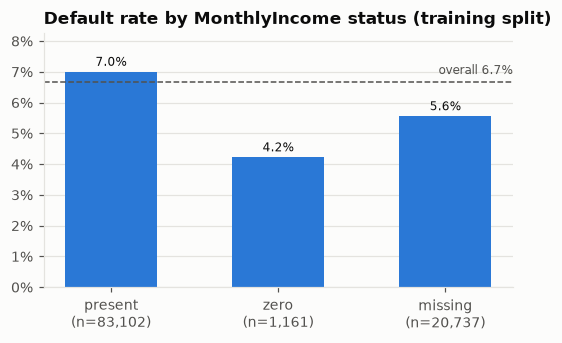

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 3))
bars = ax.bar(income_table.index, income_table["default_rate"], color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in income_table["default_rate"]], padding=2, color=INK, fontsize=8)
base_rate_line(ax); pct_axis(ax); ax.set_ylim(0, income_table["default_rate"].max() * 1.18)
ax.set_title("Default rate by MonthlyIncome status (training split)")
ax.set_xticks(range(3), [f"{s}\n(n={n:,})" for s, n in income_table["rows"].items()])
save(fig, "eda_income_status_default_rate"); plt.show()

In [24]:
# Missing income partly reflects age: the missing-income group is older, and older borrowers default less
age_band = pd.cut(train["age"], [0, 35, 50, 65, 120], labels=["≤35", "36–50", "51–65", "66+"])
y.groupby([age_band, status.where(status != "zero", "missing")], observed=True).mean().unstack().round(3)

,missing,present
age,,
≤35,0.1270,0.1080
36–50,0.0810,0.0850
51–65,0.0460,0.0580
66+,0.0150,0.0290


In [25]:
# Rows missing income or with zero income: does the DebtRatio value (a debt amount here) relate to default?
no_income = income.isna() | income.eq(0)
y[no_income].groupby(pd.qcut(train.loc[no_income, "DebtRatio"], 5), observed=True).agg(["size", "mean"])

,size,mean
DebtRatio,,
"(-0.001, 58.0]",4394,0.0473
"(58.0, 688.0]",4367,0.0783
"(688.0, 1586.0]",4380,0.0489
"(1586.0, 2708.6]",4377,0.0455
"(2708.6, 326442.0]",4380,0.0543


In [26]:
print("Rows missing dependents:", train["NumberOfDependents"].isna().sum(),
      "| default rate:", round(y[train["NumberOfDependents"].isna()].mean(), 4),
      "| all also missing income:", bool(income[train["NumberOfDependents"].isna()].isna().all()))

Rows missing dependents: 2782 | default rate: 0.0478 | all also missing income: True


## 12. Special codes 96 / 98 and invalid ages

In [27]:
coded = train[config.PAST_DUE_COLUMNS].ge(90).any(axis=1)
any_90 = ~coded & train["NumberOfTimes90DaysLate"].gt(0)
clean_history = ~coded & train[config.PAST_DUE_COLUMNS].sum(axis=1).eq(0)
pd.DataFrame({
    "rows": [coded.sum(), any_90.sum(), clean_history.sum()],
    "default_rate": [y[coded].mean(), y[any_90].mean(), y[clean_history].mean()],
}, index=["96/98 coded", "not coded, ≥1 time 90+ days late", "not coded, never past due"])

,rows,default_rate
96/98 coded,183,0.5628
"not coded, ≥1 time 90+ days late",5693,0.4105
"not coded, never past due",83730,0.0278


In [28]:
util = train["RevolvingUtilizationOfUnsecuredLines"]
print("Utilization values in coded rows:", {repr(k): v for k, v in util[coded].value_counts().items()})
print("Training rows with utilization == 0.9999999:", int((util == 0.9999999).sum()),
      "| default rate:", round(y[util == 0.9999999].mean(), 4))
print("Training rows with age < 18:", int((train["age"] < 18).sum()),
      "| age > 100:", int((train["age"] > 100).sum()))

Utilization values in coded rows: {'0.9999999': 183}
Training rows with utilization == 0.9999999: 7132 | default rate: 0.1863
Training rows with age < 18: 1 | age > 100: 8


## 13. Distributions

For the analysis below, a working copy applies the cleaning rules confirmed in Phase 2 (96/98 → missing, age < 18 →
missing). This is analysis only; the actual cleaning transformer is implemented in Phase 4.

In [29]:
eda = train.copy()
eda.loc[coded, config.PAST_DUE_COLUMNS] = np.nan
eda.loc[eda["age"] < 18, "age"] = np.nan
eda["total_past_due"] = eda[config.PAST_DUE_COLUMNS].sum(axis=1, min_count=1)

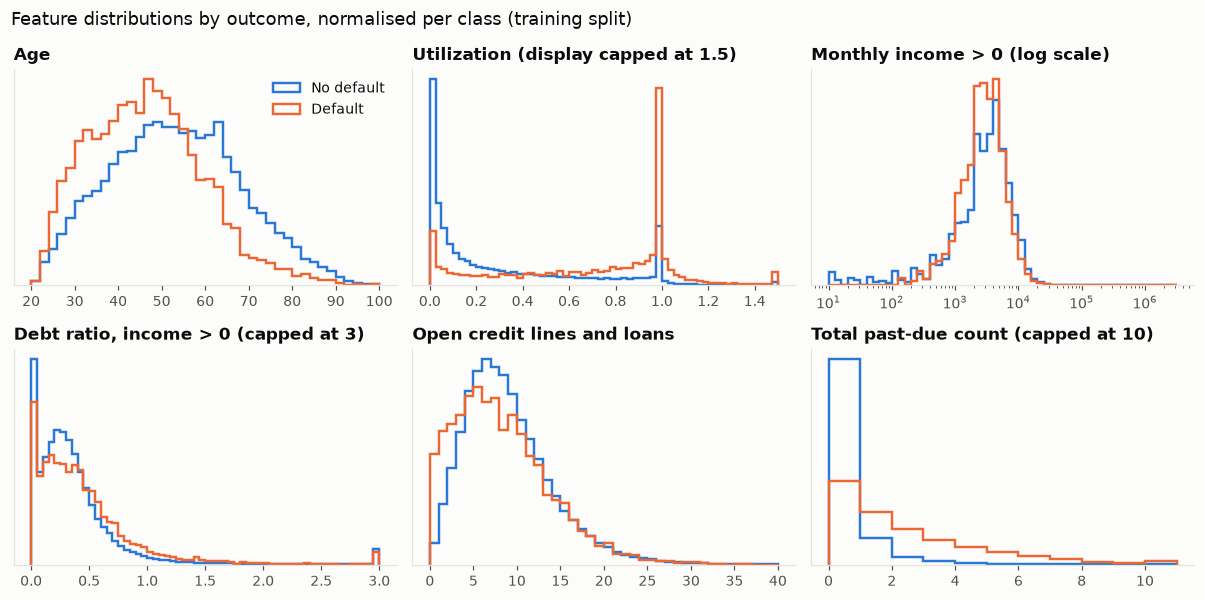

In [30]:
def class_hist(ax, values, bins, title, log_x=False):
    for cls in (0, 1):
        v = values[y == cls].dropna()
        ax.hist(v, bins=bins, density=True, histtype="step", lw=1.6, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls])
    if log_x:
        ax.set_xscale("log")
    ax.set_title(title); ax.set_yticks([]); ax.grid(False)

income_pos = eda["MonthlyIncome"].where(eda["MonthlyIncome"] > 0)
debt_ratio_with_income = eda["DebtRatio"].where(eda["MonthlyIncome"] > 0)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
class_hist(axes[0, 0], eda["age"], np.arange(20, 101, 2), "Age")
class_hist(axes[0, 1], util.clip(upper=1.5), np.linspace(0, 1.5, 61), "Utilization (display capped at 1.5)")
class_hist(axes[0, 2], income_pos, np.logspace(1, 6.5, 56), "Monthly income > 0 (log scale)", log_x=True)
class_hist(axes[1, 0], debt_ratio_with_income.clip(upper=3), np.linspace(0, 3, 61), "Debt ratio, income > 0 (capped at 3)")
class_hist(axes[1, 1], eda["NumberOfOpenCreditLinesAndLoans"], np.arange(0, 41), "Open credit lines and loans")
class_hist(axes[1, 2], eda["total_past_due"].clip(upper=10), np.arange(0, 12), "Total past-due count (capped at 10)")
axes[0, 0].legend(frameon=False, loc="upper right")
fig.suptitle("Feature distributions by outcome, normalised per class (training split)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "eda_distributions_by_target"); plt.show()

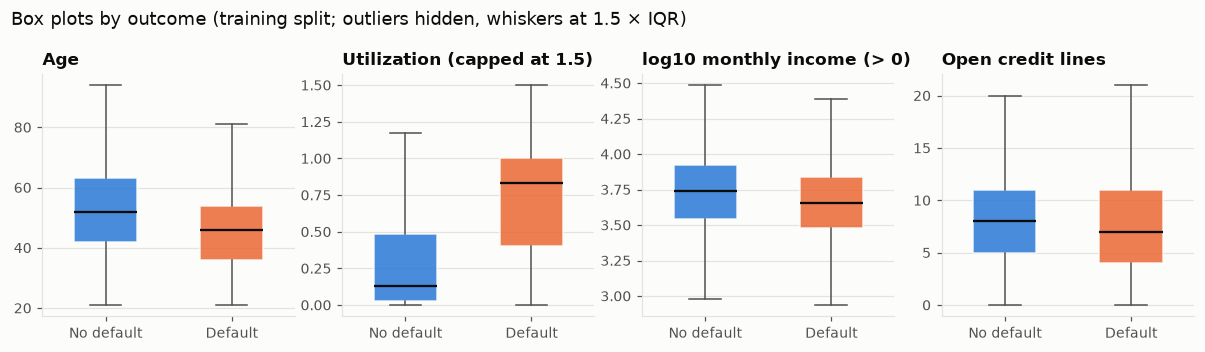

In [31]:
box_features = {
    "Age": eda["age"],
    "Utilization (capped at 1.5)": util.clip(upper=1.5),
    "log10 monthly income (> 0)": np.log10(income_pos),
    "Open credit lines": eda["NumberOfOpenCreditLinesAndLoans"],
}
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, (title, values) in zip(axes, box_features.items()):
    data = [values[y == cls].dropna() for cls in (0, 1)]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops={"color": INK, "lw": 1.5}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for patch, cls in zip(bp["boxes"], (0, 1)):
        patch.set(facecolor=CLASS_COLORS[cls], alpha=0.85, edgecolor=SURFACE)
    ax.set_xticks([1, 2], [CLASS_LABELS[0], CLASS_LABELS[1]]); ax.set_title(title)
fig.suptitle("Box plots by outcome (training split; outliers hidden, whiskers at 1.5 × IQR)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "eda_boxplots_by_target"); plt.show()

## 14. Default rate across feature ranges

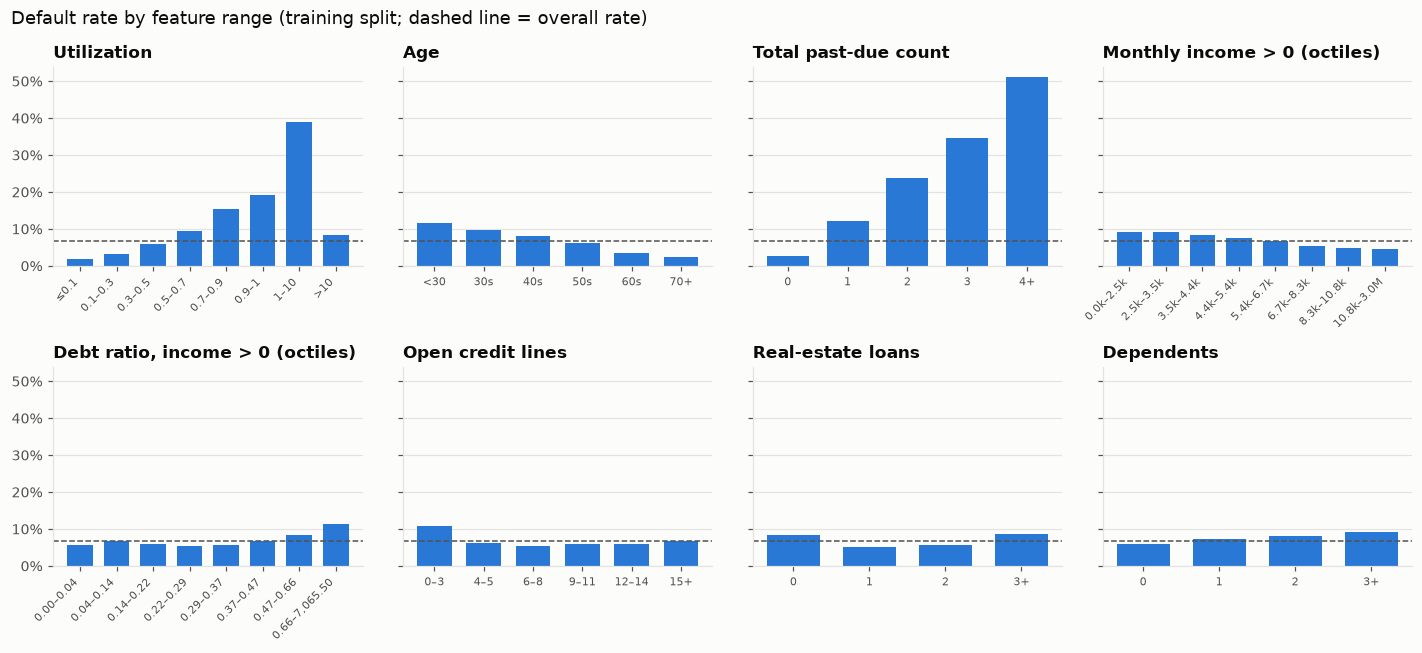

In [32]:
def rate_by_bin(series, bins=None, q=None, labels=None, fmt=lambda v: f"{v:,.2f}"):
    grouped = pd.cut(series, bins, labels=labels) if bins is not None else pd.qcut(series, q, duplicates="drop")
    out = y.groupby(grouped, observed=True).agg(rows="size", default_rate="mean")
    if labels is None:  # quantile bins: readable edges, first edge shown as the observed minimum
        edges = [series.min()] + [iv.right for iv in out.index]
        out.index = [f"{fmt(a)}–{fmt(b)}" for a, b in zip(edges[:-1], edges[1:])]
    return out

thousands = lambda v: f"{v / 1000:,.1f}k" if v < 100_000 else f"{v / 1e6:,.1f}M"

panels = {
    "Utilization": rate_by_bin(util, [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 10, np.inf],
                               labels=["≤0.1", "0.1–0.3", "0.3–0.5", "0.5–0.7", "0.7–0.9", "0.9–1", "1–10", ">10"]),
    "Age": rate_by_bin(eda["age"], [17, 30, 40, 50, 60, 70, 120], labels=["<30", "30s", "40s", "50s", "60s", "70+"]),
    "Total past-due count": rate_by_bin(eda["total_past_due"], [-1, 0, 1, 2, 3, np.inf], labels=["0", "1", "2", "3", "4+"]),
    "Monthly income > 0 (octiles)": rate_by_bin(income_pos, q=8, fmt=thousands),
    "Debt ratio, income > 0 (octiles)": rate_by_bin(debt_ratio_with_income, q=8),
    "Open credit lines": rate_by_bin(eda["NumberOfOpenCreditLinesAndLoans"], [-1, 3, 5, 8, 11, 14, np.inf],
                                     labels=["0–3", "4–5", "6–8", "9–11", "12–14", "15+"]),
    "Real-estate loans": rate_by_bin(eda["NumberRealEstateLoansOrLines"], [-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"]),
    "Dependents": rate_by_bin(eda["NumberOfDependents"], [-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"]),
}
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=True)
for ax, (title, t) in zip(axes.flat, panels.items()):
    ax.bar(range(len(t)), t["default_rate"], color=BLUE, width=0.7)
    ax.set_xticks(range(len(t)), t.index, rotation=45 if len(t) > 6 else 0, ha="right" if len(t) > 6 else "center",
                  fontsize=7.5)
    base_rate_line(ax, label=False); pct_axis(ax); ax.set_title(title)
fig.suptitle("Default rate by feature range (training split; dashed line = overall rate)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "eda_default_rate_by_feature"); plt.show()

In [33]:
# The numbers behind the chart above
pd.concat(panels, names=["feature", "range"]).assign(default_rate=lambda t: t["default_rate"].round(3))

rows  default_rate
feature                          range                             
Utilization                      ≤0.1           45209        0.0180
                                 0.1–0.3        19808        0.0310
                                 0.3–0.5        11090        0.0600
                                 0.5–0.7         7996        0.0960
                                 0.7–0.9         6963        0.1530
                                 0.9–1          11628        0.1930
                                 1–10            2141        0.3900
                                 >10              165        0.0850
Age                              <30             7515        0.1160
                                 30s            17171        0.0970
                                 40s            24517        0.0820
                                 50s            24275        0.0620
                                 60s            19128        0.0350
                                 70+            12393        0.0230
Total past-due count             0              83730        0.0280
                                 1              12111        0.1210
                                 2               4168        0.2390
                                 3               2006        0.3460
                                 4+              2802        0.5120
Monthly income > 0 (octiles)     0.0k–2.5k      10393        0.0930
                                 2.5k–3.5k      11209        0.0920
                                 3.5k–4.4k       9567        0.0840
                                 4.4k–5.4k      10384        0.0750
                                 5.4k–6.7k      10572        0.0670
                                 6.7k–8.3k      10276        0.0530
                                 8.3k–10.8k     10314        0.0490
                                 10.8k–3.0M     10387        0.0460
Debt ratio, income > 0 (octiles) 0.00–0.04      10388        0.0560
                                 0.04–0.14      10388        0.0680
                                 0.14–0.22      10387        0.0600
                                 0.22–0.29      10388        0.0530
                                 0.29–0.37      10388        0.0560
                                 0.37–0.47      10387        0.0670
                                 0.47–0.66      10388        0.0850
                                 0.66–7,065.50  10388        0.1140
Open credit lines                0–3            15381        0.1090
                                 4–5            17229        0.0630
                                 6–8            27484        0.0530
                                 9–11           20565        0.0600
                                 12–14          12074        0.0610
                                 15+            12267        0.0680
Real-estate loans                0              39313        0.0840
                                 1              36704        0.0510
                                 2              22099        0.0560
                                 3+              6884        0.0870
Dependents                       0              60701        0.0580
                                 1              18588        0.0730
                                 2              13595        0.0820
                                 3+              9334        0.0920

In [34]:
# The table behind the utilization panel, including the >10 tail
fine_util = rate_by_bin(util, [-0.01, 0.9, 1.0, 1.5, 3, 10, 100, np.inf],
                        labels=["≤0.9", "0.9–1", "1–1.5", "1.5–3", "3–10", "10–100", ">100"])
fine_util["whole_number_share"] = (util % 1 == 0).groupby(
    pd.cut(util, [-0.01, 0.9, 1.0, 1.5, 3, 10, 100, np.inf]), observed=True).mean().values
fine_util

,rows,default_rate,whole_number_share
RevolvingUtilizationOfUnsecuredLines,,,
≤0.9,91066,0.0431,0.0841
0.9–1,11628,0.1928,0.0009
1–1.5,1897,0.3922,0.0000
1.5–3,210,0.3952,0.0000
3–10,34,0.2353,0.0294
10–100,16,0.3125,0.6875
>100,149,0.0604,0.9933


## 15. Correlations

In [35]:
raw_corr = train[config.PAST_DUE_COLUMNS].corr()
clean_corr = eda[config.PAST_DUE_COLUMNS].corr()
print("Pearson correlation between past-due counts")
upper = np.triu(np.ones((3, 3), bool), 1)
print("  raw (with 96/98 codes):", raw_corr.where(upper).stack().dropna().round(3).tolist())
print("  96/98 → missing:       ", clean_corr.where(upper).stack().dropna().round(3).tolist())

Pearson correlation between past-due counts
  raw (with 96/98 codes): [0.987, 0.983, 0.993]
  96/98 → missing:        [0.305, 0.219, 0.295]


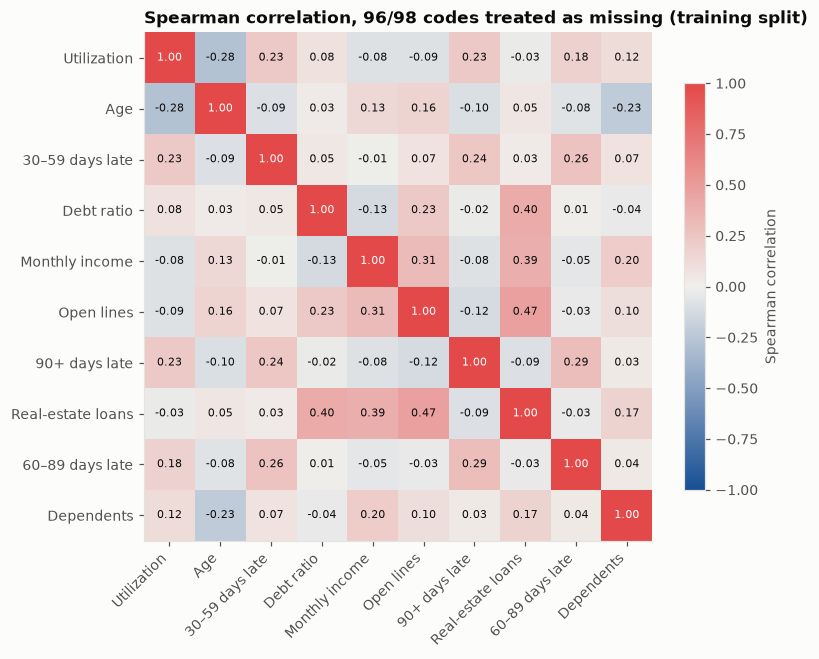

In [36]:
short = {
    "RevolvingUtilizationOfUnsecuredLines": "Utilization", "age": "Age",
    "NumberOfTime30-59DaysPastDueNotWorse": "30–59 days late", "DebtRatio": "Debt ratio",
    "MonthlyIncome": "Monthly income", "NumberOfOpenCreditLinesAndLoans": "Open lines",
    "NumberOfTimes90DaysLate": "90+ days late", "NumberRealEstateLoansOrLines": "Real-estate loans",
    "NumberOfTime60-89DaysPastDueNotWorse": "60–89 days late", "NumberOfDependents": "Dependents",
}
corr = eda[features].corr(method="spearman").rename(index=short, columns=short)
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iat[i, j]) > 0.6 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Spearman correlation, 96/98 codes treated as missing (training split)")
save(fig, "eda_correlation_matrix"); plt.show()

## 16. Candidate engineered features (SPEC §7.3)

Each candidate is computed on the working copy, then compared against its source feature using univariate ROC-AUC on
the training split (missing values filled with the median; the AUC is direction-free, `max(AUC, 1 − AUC)`). This is a
quick screening signal for deciding what to build in Phase 4, not automated feature selection.

In [37]:
def univariate_auc(s):
    auc = roc_auc_score(y, s.fillna(s.median()))
    return max(auc, 1 - auc)

no_income_clean = eda["MonthlyIncome"].isna() | eda["MonthlyIncome"].eq(0)
income_clean = eda["MonthlyIncome"].where(~no_income_clean)
candidates = {
    "total_past_due": (eda["total_past_due"], "best single past-due count"),
    "ever_90_days_late": (eda["NumberOfTimes90DaysLate"].gt(0).astype(float).where(eda["NumberOfTimes90DaysLate"].notna()),
                          "NumberOfTimes90DaysLate"),
    "monthly_income_missing": (no_income_clean.astype(float), "MonthlyIncome"),
    "income_per_dependent": (income_clean / (eda["NumberOfDependents"] + 1), "MonthlyIncome"),
    "estimated_monthly_debt": (eda["DebtRatio"] * income_clean, "DebtRatio"),
    "utilization_over_limit": (util.gt(1).astype(float), "RevolvingUtilizationOfUnsecuredLines"),
    "non_real_estate_lines": ((eda["NumberOfOpenCreditLinesAndLoans"] - eda["NumberRealEstateLoansOrLines"]).clip(lower=0),
                              "NumberOfOpenCreditLinesAndLoans"),
}
source_auc = {c: univariate_auc(eda[c]) for c in features}
source_auc["MonthlyIncome"] = univariate_auc(income_clean)
source_auc["best single past-due count"] = max(source_auc[c] for c in config.PAST_DUE_COLUMNS)
pd.DataFrame([
    {"candidate": name, "candidate_auc": univariate_auc(s), "compared_with": src, "source_auc": source_auc[src]}
    for name, (s, src) in candidates.items()
]).round(4)

,candidate,candidate_auc,compared_with,source_auc
0,total_past_due,0.7647,best single past-due count,0.6785
1,ever_90_days_late,0.6494,NumberOfTimes90DaysLate,0.6506
2,monthly_income_missing,0.5201,MonthlyIncome,0.5723
3,income_per_dependent,0.5886,MonthlyIncome,0.5723
4,estimated_monthly_debt,0.5092,DebtRatio,0.5207
5,utilization_over_limit,0.5531,RevolvingUtilizationOfUnsecuredLines,0.7775
6,non_real_estate_lines,0.5481,NumberOfOpenCreditLinesAndLoans,0.5483


In [38]:
pd.DataFrame({c: [univariate_auc(eda[c])] for c in features}, index=["univariate AUC"]).T.sort_values(
    "univariate AUC", ascending=False).round(4)

,univariate AUC
RevolvingUtilizationOfUnsecuredLines,0.7775
NumberOfTime30-59DaysPastDueNotWorse,0.6785
NumberOfTimes90DaysLate,0.6506
age,0.6324
NumberOfTime60-89DaysPastDueNotWorse,0.6142
MonthlyIncome,0.5686
NumberOfOpenCreditLinesAndLoans,0.5483
NumberOfDependents,0.5482
NumberRealEstateLoansOrLines,0.5388
DebtRatio,0.5207


## Part 2 findings and decisions

### Key findings (training split, 105,000 rows, 6.68% default)

| Topic | Finding |
|---|---|
| **Past-due history** | The strongest signal. Default rate 2.8% with no past-due events, rising to 12% (1 event), 24% (2), 35% (3) and 51% (4+). The 96/98-coded rows default at **56%** (183 rows) |
| **Utilization** | Strong and monotonic up to 1.0: 1.8% at ≤ 0.1 → 19% at 0.9–1 → **39%** at 1–1.5, a sharp jump just above 1.0. 7,132 rows sit at exactly 0.9999999 (a capped value; 18.6% default) |
| **Utilization > 10** | Behaves differently: the 149 rows above 100 are 99% whole numbers with a 6% default rate, so they look like amounts, not ratios. 16 rows between 10 and 100 are ambiguous |
| **Age** | Clear monotonic decline: 11.6% under 30 → 2.3% at 70+ |
| **Income** | Mild, steady decline: 9.3% in the lowest octile → 4.6% in the highest |
| **Zero / missing income** | Default rate 7.0% when income > 0, **4.2%** when 0, **5.6%** when missing. In both the zero and missing groups `DebtRatio` is 100% whole numbers (medians 924 and 1,160), so it holds a debt amount, not a ratio. That amount shows no consistent link to default (4.5–7.8% across quintiles) |
| **Missingness and age** | The missing-income group is older (median 57 vs 51), which explains part of its lower rate. Within age bands the difference is mixed |
| **Debt ratio (income > 0)** | Weak and non-linear: flat around 5–7% until about 0.5, then rising to 11% |
| **Open lines / real-estate loans** | U-shaped: 0–3 open lines → 10.9%; real-estate loans 0 → 8.4%, 1–2 → 5–6%, 3+ → 8.7% |
| **Dependents** | Weak increase: 5.8% (0) → 9.2% (3+) |
| **Correlations** | Raw Pearson correlation between the three past-due counts is 0.98–0.99, **entirely an artefact of the 96/98 codes**; it drops to 0.22–0.31 once they are missing. The largest remaining Spearman correlation is 0.47 (open lines vs real-estate loans), so there is no severe multicollinearity and no need to drop features |
| **Imbalance** | About 1 : 14, as expected |

### Decisions: cleaning rules (stateless, implemented in Phase 4)

1. **Past-due values ≥ 90 → missing** (confirmed). The coded group is high-risk (56%), so the missingness must stay
   visible to the models: XGBoost handles NaN natively, and Logistic Regression gets missing indicators (SPEC §8).
2. **`age` < 18 → missing** (confirmed; 1 training row).
3. **`MonthlyIncome == 0` → missing** *(new)*. `DebtRatio` behaves exactly as when income is missing, so the ratio
   was never computed and income is effectively unknown.
4. **`DebtRatio` → missing when income is missing** (after rule 3) *(new)*. For those rows the value is a debt
   amount, not a ratio. Keeping it would mix two units in one column and distort scaling and winsorizing for Logistic
   Regression. It shows no consistent link to default, so little information is lost.
5. **Utilization > 10 → missing** *(new)*. Values above 1,000% are not plausible utilization ratios, and above 100
   they behave like amounts. This affects 165 training rows (0.16%).

**Kept as genuine:** duplicates, ages 101–109, utilization 1–10 (genuinely over the limit, high risk), and the
0.9999999 cap value.

### Decisions: engineered features for Phase 4 (SPEC §7.3)

| Candidate | Decision | Reason |
|---|---|---|
| `total_past_due` | **Build** | Univariate AUC 0.765 vs 0.679 for the best single count |
| `income_per_dependent` | **Build** | AUC 0.589 vs 0.572 for income alone |
| `utilization_over_limit` | **Build** | Captures the jump in default rate at 1.0 (19% → 39%) that a linear model cannot represent from the raw value |
| `ever_90_days_late` | Skip | No gain over `NumberOfTimes90DaysLate` (0.649 vs 0.651) |
| `monthly_income_missing` | Skip | Duplicates information already provided by XGBoost's native NaN handling and Logistic Regression's missing indicators |
| `estimated_monthly_debt` | Skip | Weakest candidate (AUC 0.509, below `DebtRatio` itself) |
| `non_real_estate_lines` | Skip | No gain over open lines (0.548 vs 0.548) |

### Implications for preprocessing (SPEC §8, unchanged)

- Utilization, debt ratio, income, `income_per_dependent` and the count features are strongly right-skewed. This
  confirms Logistic Regression's winsorizing and `log1p` steps.
- Several relationships are non-linear (open lines and real-estate loans are U-shaped; debt ratio only matters above
  about 0.5). A linear baseline will miss these, which is why tree models are part of the comparison.
- `age` is one of the strongest predictors and is a protected attribute. This is recorded for the responsible-ML
  discussion (SPEC §21).